In [471]:
import pandas as pd
import seaborn as sns
import matplotlib.pylab as plt
import numpy as np

In [473]:
df=pd.read_csv("traffic accident predictions.csv")

In [475]:
df.head()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,Rainy,City Road,Morning,1.0,100.0,5.0,0.0,NaN,Wet,Car,51.0,48.0,Artificial Light,0.0
1,Clear,Rural Road,Night,NaN,120.0,3.0,0.0,Moderate,Wet,Truck,49.0,43.0,Artificial Light,0.0
2,Rainy,Highway,Evening,1.0,60.0,4.0,0.0,Low,Icy,Car,54.0,52.0,Artificial Light,0.0
3,Clear,City Road,Afternoon,2.0,60.0,3.0,0.0,Low,Under Construction,Bus,34.0,31.0,Daylight,0.0
4,Rainy,Highway,Morning,1.0,195.0,11.0,0.0,Low,Dry,Car,62.0,55.0,Artificial Light,1.0


In [477]:
df.shape

(840, 14)

In [479]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 840 entries, 0 to 839
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Weather               798 non-null    object 
 1   Road_Type             798 non-null    object 
 2   Time_of_Day           798 non-null    object 
 3   Traffic_Density       798 non-null    float64
 4   Speed_Limit           798 non-null    float64
 5   Number_of_Vehicles    798 non-null    float64
 6   Driver_Alcohol        798 non-null    float64
 7   Accident_Severity     798 non-null    object 
 8   Road_Condition        798 non-null    object 
 9   Vehicle_Type          798 non-null    object 
 10  Driver_Age            798 non-null    float64
 11  Driver_Experience     798 non-null    float64
 12  Road_Light_Condition  798 non-null    object 
 13  Accident              798 non-null    float64
dtypes: float64(7), object(7)
memory usage: 92.0+ KB


In [481]:
df.isnull()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,False,False,False,False,False,False,False,True,False,False,False,False,False,False
1,False,False,False,True,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
835,False,False,False,False,False,False,False,False,False,False,False,False,False,False
836,False,False,False,False,False,False,False,False,False,False,False,False,False,False
837,False,False,False,True,False,False,False,False,False,False,True,False,False,True
838,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [483]:
df.isnull().sum()

Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density         42
Speed_Limit             42
Number_of_Vehicles      42
Driver_Alcohol          42
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age              42
Driver_Experience       42
Road_Light_Condition    42
Accident                42
dtype: int64

In [485]:
df.isnull().sum().sum()

588

In [487]:
(df.isnull().sum()/df.shape[0]*100)

Weather                 5.0
Road_Type               5.0
Time_of_Day             5.0
Traffic_Density         5.0
Speed_Limit             5.0
Number_of_Vehicles      5.0
Driver_Alcohol          5.0
Accident_Severity       5.0
Road_Condition          5.0
Vehicle_Type            5.0
Driver_Age              5.0
Driver_Experience       5.0
Road_Light_Condition    5.0
Accident                5.0
dtype: float64

In [489]:
(df.isnull().sum().sum()/(df.shape[0]*df.shape[1])*100)

5.0

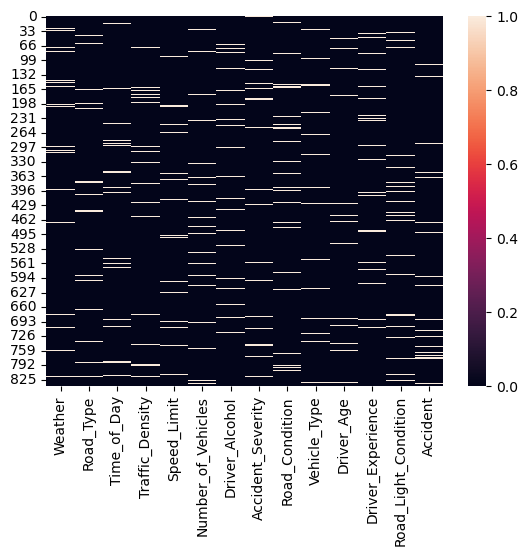

In [491]:
sns.heatmap(df.isnull())
plt.show()

# Numerical Attributes (fill null column using median)

# Traffic Density

In [494]:
df.select_dtypes(include="float").columns

Index(['Traffic_Density', 'Speed_Limit', 'Number_of_Vehicles',
       'Driver_Alcohol', 'Driver_Age', 'Driver_Experience', 'Accident'],
      dtype='object')

In [495]:
for i in df.select_dtypes(include="float").columns:
    print(i)
    df.fillna({i: df[i].mode()[0]}, inplace=True)

Traffic_Density
Speed_Limit
Number_of_Vehicles
Driver_Alcohol
Driver_Age
Driver_Experience
Accident


In [497]:
df.isnull().sum()

Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density          0
Speed_Limit              0
Number_of_Vehicles       0
Driver_Alcohol           0
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age               0
Driver_Experience        0
Road_Light_Condition    42
Accident                 0
dtype: int64

In [501]:
df.select_dtypes(include="float").columns

Index(['Traffic_Density', 'Speed_Limit', 'Number_of_Vehicles',
       'Driver_Alcohol', 'Driver_Age', 'Driver_Experience', 'Accident'],
      dtype='object')

In [503]:
from sklearn.impute import SimpleImputer

In [505]:
si = SimpleImputer(strategy ='median')

In [507]:
ar = si.fit_transform(df[['Traffic_Density', 'Speed_Limit', 'Number_of_Vehicles',
       'Driver_Alcohol', 'Driver_Age', 'Driver_Experience', 'Accident']])
print(ar)

[[  1. 100.   5. ...  51.  48.   0.]
 [  1. 120.   3. ...  49.  43.   0.]
 [  1.  60.   4. ...  54.  52.   0.]
 ...
 [  1.  30.   4. ...  46.  34.   0.]
 [  2.  60.   3. ...  25.  19.   0.]
 [  1.  60.   4. ...  29.  21.   0.]]


In [509]:
new_df = pd.DataFrame(ar,columns=df.select_dtypes(include="float64").columns)

In [511]:
new_df.isnull().sum()

Traffic_Density       0
Speed_Limit           0
Number_of_Vehicles    0
Driver_Alcohol        0
Driver_Age            0
Driver_Experience     0
Accident              0
dtype: int64

# Categorical Attributes (fill null column using mode)

In [514]:
df["Weather"].mode()
df["Weather"].mode()[0]

'Clear'

In [516]:
df.fillna({"Weather": df["Weather"].mode()[0]}, inplace=True)

In [518]:
df.select_dtypes(include="object").columns

Index(['Weather', 'Road_Type', 'Time_of_Day', 'Accident_Severity',
       'Road_Condition', 'Vehicle_Type', 'Road_Light_Condition'],
      dtype='object')

In [520]:
for i in df.select_dtypes(include="object").columns:
    print(i)
    df.fillna({i: df[i].mode()[0]}, inplace=True)

Weather
Road_Type
Time_of_Day
Accident_Severity
Road_Condition
Vehicle_Type
Road_Light_Condition


In [522]:
df.isnull().sum()

Weather                 0
Road_Type               0
Time_of_Day             0
Traffic_Density         0
Speed_Limit             0
Number_of_Vehicles      0
Driver_Alcohol          0
Accident_Severity       0
Road_Condition          0
Vehicle_Type            0
Driver_Age              0
Driver_Experience       0
Road_Light_Condition    0
Accident                0
dtype: int64

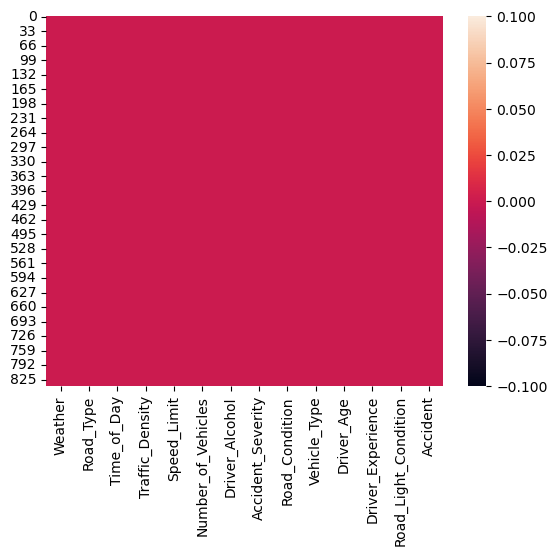

In [524]:
sns.heatmap(df.isnull())
plt.show()

In [525]:
df.select_dtypes(include="float").columns

Index(['Traffic_Density', 'Speed_Limit', 'Number_of_Vehicles',
       'Driver_Alcohol', 'Driver_Age', 'Driver_Experience', 'Accident'],
      dtype='object')

In [528]:
from sklearn.impute import SimpleImputer

In [530]:
si = SimpleImputer(strategy ='median')

In [532]:
ar = si.fit_transform(df[['Traffic_Density', 'Speed_Limit', 'Number_of_Vehicles',
       'Driver_Alcohol', 'Driver_Age', 'Driver_Experience', 'Accident']])
print(ar)

[[  1. 100.   5. ...  51.  48.   0.]
 [  1. 120.   3. ...  49.  43.   0.]
 [  1.  60.   4. ...  54.  52.   0.]
 ...
 [  1.  30.   4. ...  46.  34.   0.]
 [  2.  60.   3. ...  25.  19.   0.]
 [  1.  60.   4. ...  29.  21.   0.]]


In [534]:
new_df = pd.DataFrame(ar,columns=df.select_dtypes(include="float64").columns)

In [536]:
new_df.isnull().sum()

Traffic_Density       0
Speed_Limit           0
Number_of_Vehicles    0
Driver_Alcohol        0
Driver_Age            0
Driver_Experience     0
Accident              0
dtype: int64

In [538]:
df.head()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,Rainy,City Road,Morning,1.0,100.0,5.0,0.0,Low,Wet,Car,51.0,48.0,Artificial Light,0.0
1,Clear,Rural Road,Night,1.0,120.0,3.0,0.0,Moderate,Wet,Truck,49.0,43.0,Artificial Light,0.0
2,Rainy,Highway,Evening,1.0,60.0,4.0,0.0,Low,Icy,Car,54.0,52.0,Artificial Light,0.0
3,Clear,City Road,Afternoon,2.0,60.0,3.0,0.0,Low,Under Construction,Bus,34.0,31.0,Daylight,0.0
4,Rainy,Highway,Morning,1.0,195.0,11.0,0.0,Low,Dry,Car,62.0,55.0,Artificial Light,1.0


In [ ]:
df.reset_index(drop=True, inplace=True)
df.to_excel("cleaned_file.xlsx", index=False)

#Visualisation#

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [361]:
Weather_nc = LabelEncoder()
df["Weather"] = Weather_nc.fit_transform(df["Weather"])

In [363]:
Road_Type_nc = LabelEncoder()
df["Road_Type"] = Road_Type_nc.fit_transform(df["Road_Type"])

In [365]:
Time_of_Day_nc = LabelEncoder()
df["Time_of_Day"] = Time_of_Day_nc.fit_transform(df["Time_of_Day"])

In [367]:
Traffic_Density_nc = LabelEncoder()
df["Traffic_Density"] = Traffic_Density_nc.fit_transform(df["Traffic_Density"])

In [369]:
Speed_Limit_nc = LabelEncoder()
df["Speed_Limit"] = Speed_Limit_nc.fit_transform(df["Speed_Limit"])

In [371]:
Number_of_Vehicles_nc = LabelEncoder()
df["Number_of_Vehicles"] = Number_of_Vehicles_nc.fit_transform(df["Number_of_Vehicles"])

In [373]:
Driver_Alcohol_nc = LabelEncoder()
df["Driver_Alcohol"] = Driver_Alcohol_nc.fit_transform(df["Driver_Alcohol"])

In [375]:
Accident_Severity_nc = LabelEncoder()
df["Accident_Severity"] = Accident_Severity_nc.fit_transform(df["Accident_Severity"])

In [377]:
Road_Condition_nc = LabelEncoder()
df["Road_Condition"] = Road_Condition_nc.fit_transform(df["Road_Condition"])

In [379]:
Vehicle_Type_nc = LabelEncoder()
df["Vehicle_Type"] = Vehicle_Type_nc.fit_transform(df["Vehicle_Type"])

In [381]:
Driver_Age_nc = LabelEncoder()
df["Driver_Age"] = Driver_Age_nc.fit_transform(df["Driver_Age"])

In [383]:
Driver_Experience_nc = LabelEncoder()
df["Driver_Experience"] = Driver_Experience_nc.fit_transform(df["Driver_Experience"])

In [385]:
Road_Light_Condition_nc = LabelEncoder()
df["Road_Light_Condition"] = Road_Light_Condition_nc.fit_transform(df["Road_Light_Condition"])

In [387]:
Accident_nc = LabelEncoder()
df["Accident"] = Accident_nc.fit_transform(df["Accident"])

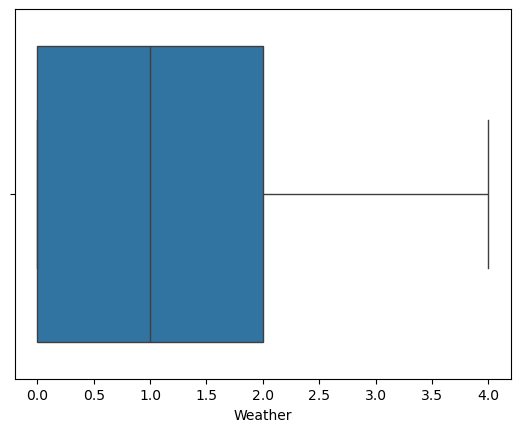

In [389]:
sns.boxplot(x = "Weather", data = df)
plt.show()

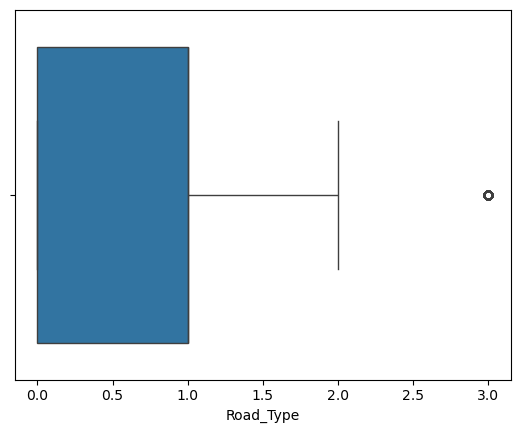

In [390]:
sns.boxplot(x = "Road_Type", data = df)
plt.show()

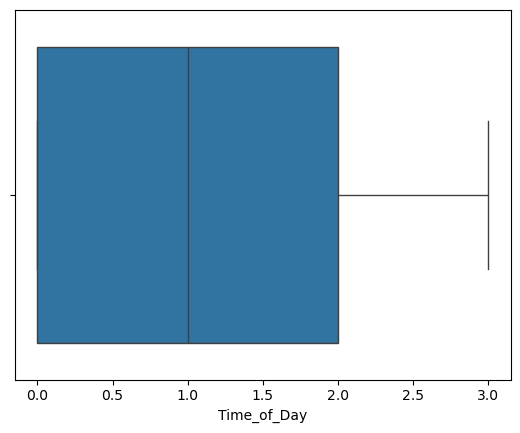

In [392]:
sns.boxplot(x = "Time_of_Day", data = df)
plt.show()

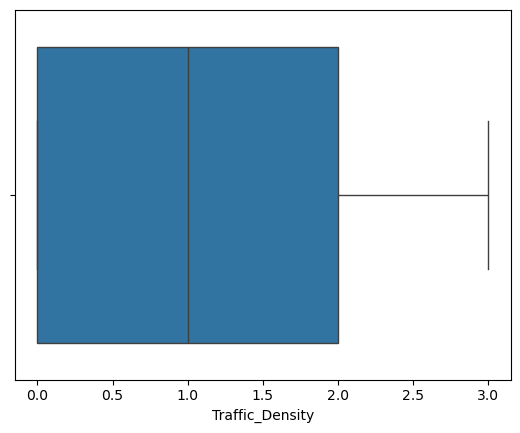

In [394]:
sns.boxplot(x = "Traffic_Density", data = df)
plt.show()

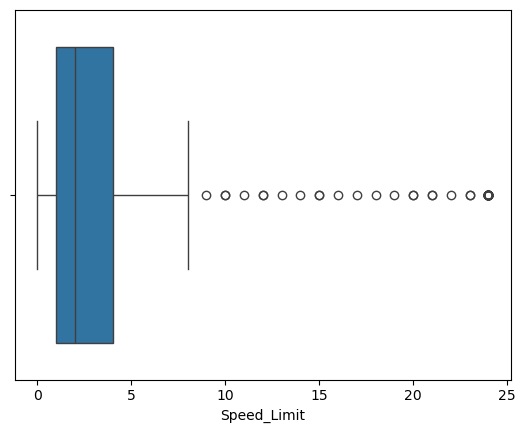

In [396]:
sns.boxplot(x = "Speed_Limit", data = df)
plt.show()

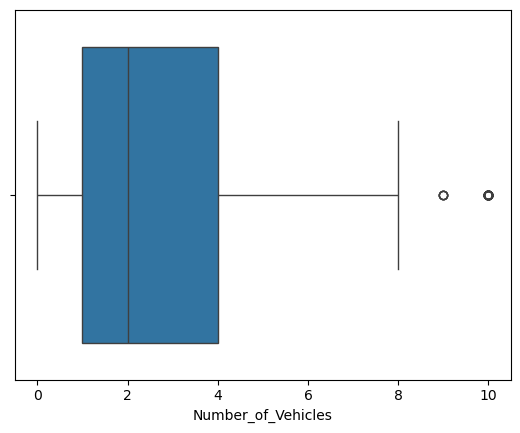

In [397]:
sns.boxplot(x = "Number_of_Vehicles", data = df)
plt.show()

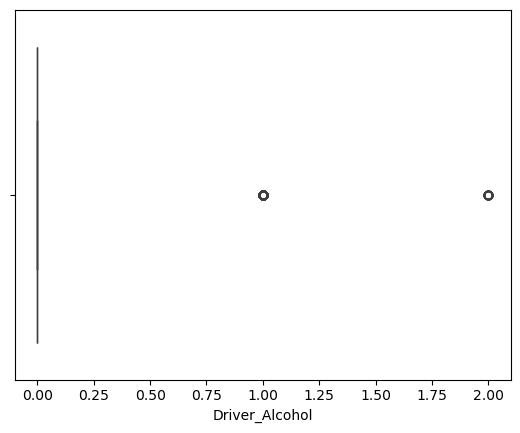

In [401]:
sns.boxplot(x = "Driver_Alcohol", data = df)
plt.show()

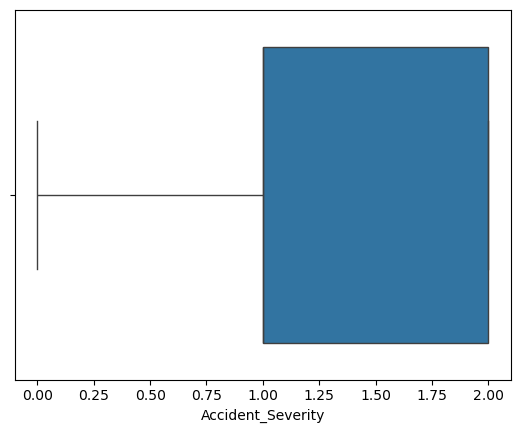

In [403]:
sns.boxplot(x = "Accident_Severity", data = df)
plt.show()

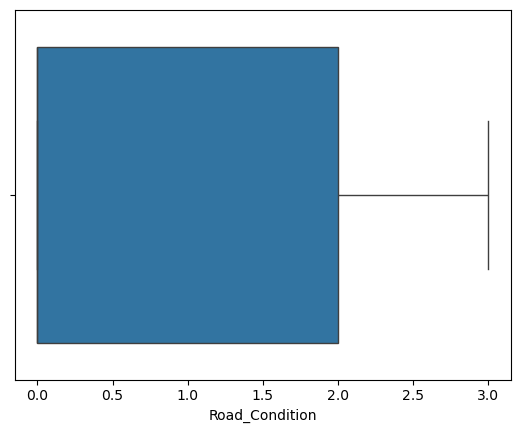

In [405]:
sns.boxplot(x = "Road_Condition", data = df)
plt.show()

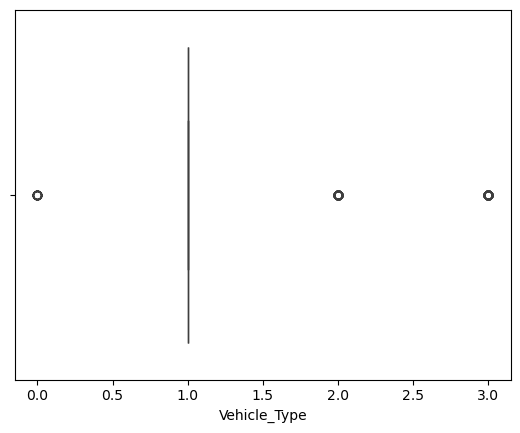

In [407]:
sns.boxplot(x = "Vehicle_Type", data = df)
plt.show()

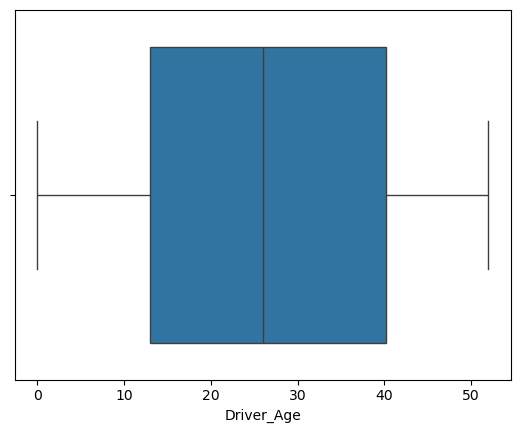

In [409]:
sns.boxplot(x = "Driver_Age", data = df)
plt.show()

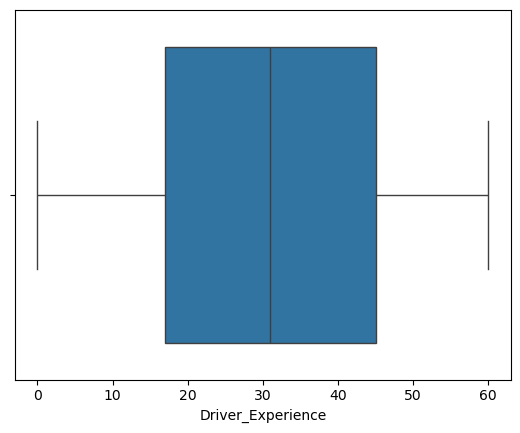

In [411]:
sns.boxplot(x = "Driver_Experience", data = df)
plt.show()

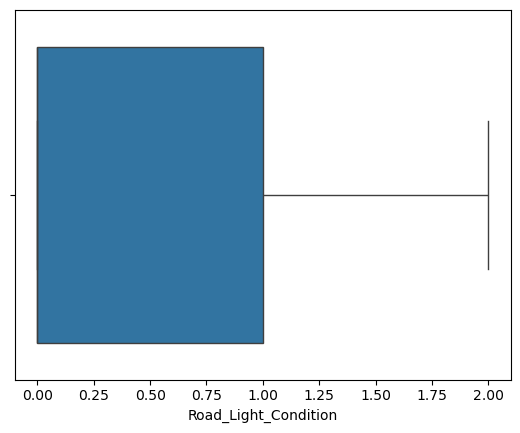

In [413]:
sns.boxplot(x = "Road_Light_Condition", data = df)
plt.show()

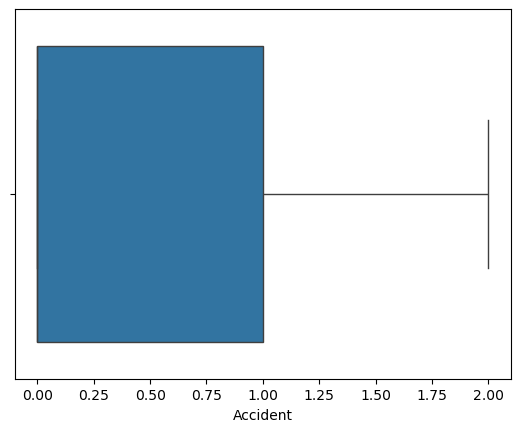

In [415]:
sns.boxplot(x = "Accident", data = df)
plt.show()

In [417]:
q1 = np.quantile(df['Road_Type'], 0.25)
q3 = np.quantile(df['Road_Type'], 0.75)
iqr = q3 - q1
min_r = q1 - (1.5*iqr)
max_r = q3 + (1.5*iqr)
min_r , max_r

(-1.5, 2.5)

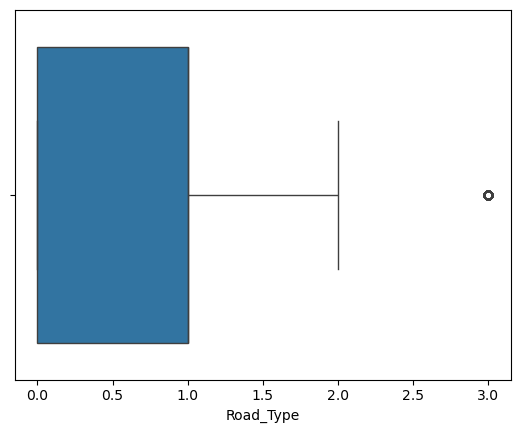

In [419]:
df = df[df["Road_Type"]<=3]
sns.boxplot(x="Road_Type", data=df)
plt.show()

In [423]:
q1 = np.quantile(df['Speed_Limit'], 0.25)
q3 = np.quantile(df['Speed_Limit'], 0.75)
iqr = q3 - q1
min_r = q1 - (1.5*iqr)
max_r = q3 + (1.5*iqr)
min_r , max_r

(-3.5, 8.5)

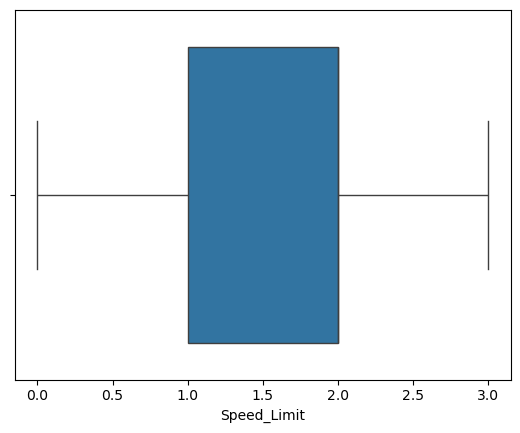

In [425]:
df = df[df["Speed_Limit"]<=3]
sns.boxplot(x="Speed_Limit", data=df)
plt.show()

In [427]:
q1 = np.quantile(df['Number_of_Vehicles'], 0.25)
q3 = np.quantile(df['Number_of_Vehicles'], 0.75)
iqr = q3 - q1
min_r = q1 - (1.5*iqr)
max_r = q3 + (1.5*iqr)
min_r , max_r

(-2.0, 6.0)

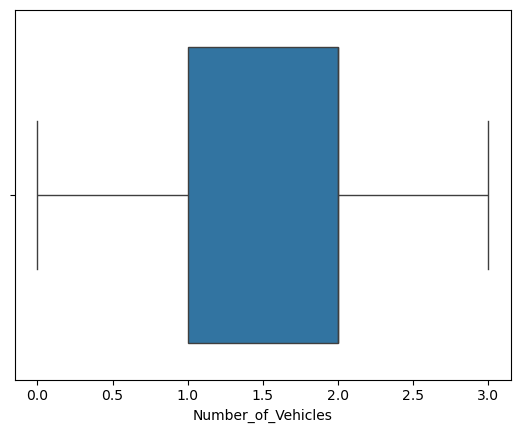

In [429]:
df = df[df["Number_of_Vehicles"]<=3]
sns.boxplot(x="Number_of_Vehicles", data=df)
plt.show()

In [433]:
q1 = np.quantile(df['Driver_Alcohol'], 0.25)
q3 = np.quantile(df['Driver_Alcohol'], 0.75)
iqr = q3 - q1
min_r = q1 - (1.5*iqr)
max_r = q3 + (1.5*iqr)
min_r , max_r

(0.0, 0.0)

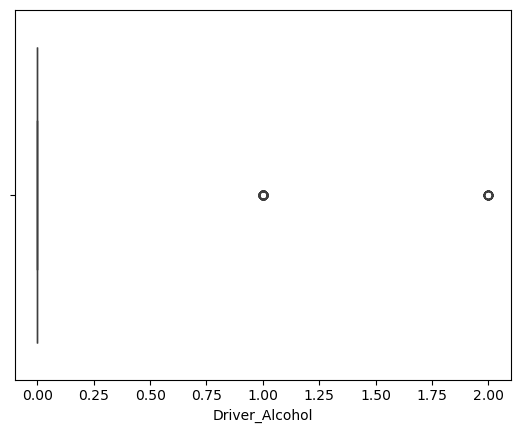

In [435]:
df = df[df["Driver_Alcohol"]<=3]
sns.boxplot(x="Driver_Alcohol", data=df)
plt.show()

In [441]:
q1 = np.quantile(df['Vehicle_Type'], 0.25)
q3 = np.quantile(df['Vehicle_Type'], 0.75)
iqr = q3 - q1
min_r = q1 - (1.5*iqr)
max_r = q3 + (1.5*iqr)
min_r , max_r

(1.0, 1.0)

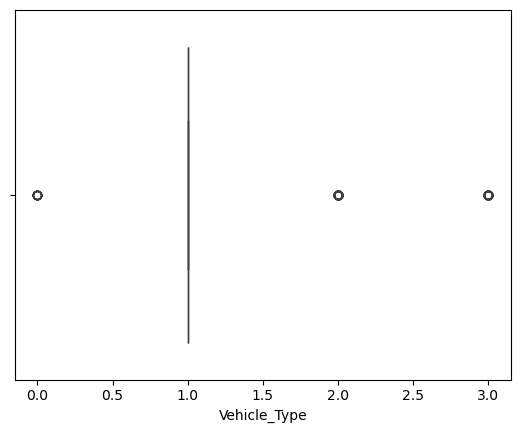

In [443]:
df = df[df["Vehicle_Type"]<=3]
sns.boxplot(x="Vehicle_Type", data=df)
plt.show()

In [449]:
ss = StandardScaler()
new_df = pd.DataFrame(ss.fit_transform(df), columns = df.columns)
new_df

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,0.707734,-0.076330,-0.118580,-0.143272,0.297861,1.344519,-0.486099,-0.263107,0.128975,-0.418301,0.592567,0.751132,-0.919583,-0.665872
1,-0.954824,-1.103515,-1.065207,0.981413,0.297861,0.446266,-0.486099,-0.263107,1.022316,-1.888597,-0.662375,-0.555259,0.543672,-0.665872
2,-0.123545,-0.076330,-1.065207,-1.267957,0.297861,1.344519,-0.486099,-0.263107,-0.764366,2.522292,-1.101604,-0.866304,0.543672,1.038615
3,0.707734,-1.103515,-1.065207,-1.267957,0.297861,1.344519,-0.486099,-0.263107,-0.764366,-0.418301,-0.976110,-1.115141,-0.919583,1.038615
4,2.370292,-0.076330,0.828047,-0.143272,0.297861,-0.451987,-0.486099,-1.984264,0.128975,-0.418301,-0.411386,-0.679677,-0.919583,-0.665872
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,-0.954824,-0.076330,1.774675,0.981413,-1.750207,1.344519,-0.486099,-0.263107,-0.764366,-0.418301,-1.352593,-1.550604,0.543672,-0.665872
467,0.707734,1.978040,-0.118580,0.981413,0.297861,1.344519,-0.486099,-0.263107,-0.764366,1.051996,0.467073,0.377877,0.543672,1.038615
468,-0.123545,-0.076330,-0.118580,2.106098,-1.750207,1.344519,1.302592,-1.984264,-0.764366,-0.418301,1.596520,-0.368632,-0.919583,2.743102
469,-0.123545,-0.076330,-1.065207,0.981413,0.297861,0.446266,-0.486099,-0.263107,-0.764366,-0.418301,-1.227099,-1.301768,-0.919583,-0.665872


In [451]:
df.columns

Index(['Weather', 'Road_Type', 'Time_of_Day', 'Traffic_Density', 'Speed_Limit',
       'Number_of_Vehicles', 'Driver_Alcohol', 'Accident_Severity',
       'Road_Condition', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience',
       'Road_Light_Condition', 'Accident'],
      dtype='object')

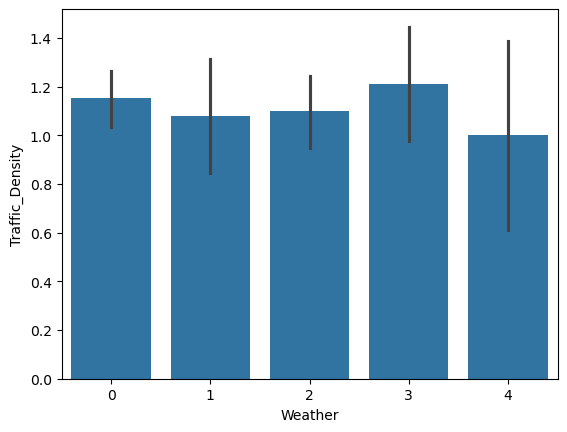

In [455]:
sns.barplot(x="Weather",y="Traffic_Density",data=df)
plt.show()

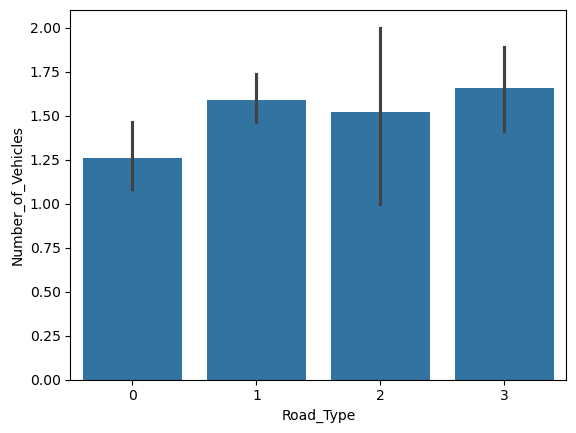

In [457]:
sns.barplot(x="Road_Type",y="Number_of_Vehicles",data=df)
plt.show()

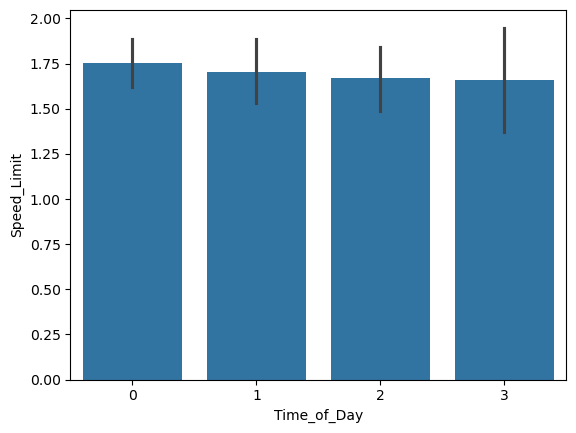

In [459]:
sns.barplot(x="Time_of_Day",y="Speed_Limit",data=df)
plt.show()

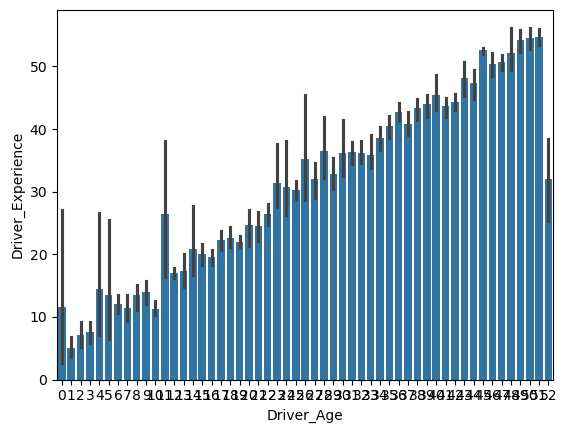

In [461]:
sns.barplot(x="Driver_Age",y="Driver_Experience",data=df)
plt.show()